# Table of Contents
- 1. Formulating Hypotheses from Visualizations
- 2. Segment-Based Deep Dives (Slicing and Dicing)
- 3. Identifying Confounders and Simpson’s Paradox in EDA
- 4. Translating Findings into Actionable Insights

In [ ]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for EDA story extraction framework loaded successfully.")

#### 1. Formulating Hypotheses from Visualizations
Given observed sample statistic difference $\Delta \hat{\theta}$, the test statistic $T$ evaluates the null hypothesis $H_0: \theta_1 = \theta_2$ against standard error $se$:
$$T = \frac{\hat{\theta}_1 - \hat{\theta}_2}{se(\hat{\theta}_1 - \hat{\theta}_2)}$$
- $\hat{\theta}_1$: "Estimated parameter for group 1"
- $H_0$: "Null hypothesis baseline model"
- $T$: "Test statistic"

| Notation | How to Pronounce | What It Means |
| :--- | :--- | :--- |
| $\Delta$ | "Delta" | Change or difference |
| $\theta$ | "Theta" | A population parameter (the true value you want to estimate) |
| $\hat{\theta}$ | "Theta hat" | An **estimate** of the parameter calculated from sample data (the "hat" symbol $\hat{}$ always indicates an estimate) |
| $\theta_1$, $\theta_2$ | "Theta one", "Theta two" | The parameters for group 1 and group 2 |
| $\hat{\theta}_1$, $\hat{\theta}_2$ | "Theta one hat", "Theta two hat" | The sample estimates for group 1 and group 2 |
| $\Delta \hat{\theta}$ | "Delta theta hat" | The observed difference between the two sample estimates ($\hat{\theta}_1 - \hat{\theta}_2$) |
| $H_0$ | "H-naught" (or "H-zero") | The **null hypothesis** (the baseline assumption that there is no real difference) |
| $T$ | "T" | The **test statistic** (the final calculated number used to make your decision) |
| $se$ | "S-E" (or "Standard error") | Standard error (how much random sampling variation to expect) |
| $se(\hat{\theta}_1 - \hat{\theta}_2)$ | "Standard error of theta one hat minus theta two hat" | The standard error of the difference between the two group estimates |

In [ ]:
np.random.seed(42)
df_hyp = pd.DataFrame({
    'device': ['Mobile'] * 100 + ['Desktop'] * 100,
    'conversion': np.concatenate([np.random.binomial(1, 0.05, 100), np.random.binomial(1, 0.12, 100)])
})

# example of monomial expression is : y = x^2
# example of binomial expression is : y = x^2 + x or y = x^2 - x
# example of trinomial expression is : y = x^2 + x + 1
# example of polynomial expression of degree 4 is : y = x^4 + x^3 + x^2 + x + 1
# example of polynomial expression of degree 5 is : y = x^5 + x^4 + x^3 + x^2 + x + 1

# print(df_hyp)
conversion_rate_by_device = df_hyp.groupby('device')['conversion'].mean()
print("Conversion rate by device:\n", conversion_rate_by_device)

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='device', y='conversion', hue='device', data=df_hyp, palette='Blues_d', legend=False, errorbar=None)
plt.title('Visual Hypothesis: Conversion Rate by Device Type')
plt.ylabel('Conversion Probability')
plt.show()


In [ ]:
from scipy import stats
np.random.seed(42)

# Control Group (Standard Practice): Average strike rate around 125
control_group = np.random.normal(loc=125.0, scale=8.0, size=25)
# print("Control Group Strike Rates:\n", control_group)

# Treatment Group (Power-Hitting Camp): Average strike rate around 135
camp_group = np.random.normal(loc=135.0, scale=8.0, size=25)
# print("Treatment Group Strike Rates:\n", camp_group)

# Formulating Hypotheses 
# Null Hypothesis (H0): The average strike rate of the control group is equal to the average strike rate of the Power Hitting Camp group.
# Alternative Hypothesis (H1): The average strike rate of the Power Hitting Camp group is higher than that of the control group.

# run independent one-sided t-test (testing if the Power Hitting Camp group has a higher average strike rate than the control group)
# t-test : means comparison between two independent groups : one-sided test to check if the mean of the first group is greater than the mean of the second group
t_statistics, p_value = stats.ttest_ind(camp_group, control_group, alternative='greater')

print(f"Average Strike Rate - Control Group: {np.mean(control_group):.2f}")
print(f"Average Strike Rate - Power Hitting Camp Group: {np.mean(camp_group):.2f}")
print("_" * 60)
print(f"T-Statistics: {t_statistics:.2f}")
print(f"P-Value: {p_value:.4f}")
print("_" * 60)
if p_value < 0.05:
    print("Result: Reject the null hypothesis. The Power Hitting Camp group has a significantly higher average strike rate.")
else:
    print("Result: Fail to reject the null hypothesis. There is no significant difference in average strike rates.")



Average Strike Rate - Control Group: 123.69
Average Strike Rate - Power Hitting Camp Group: 132.70
____________________________________________________________
T-Statistics: 4.23
P-Value: 0.0001
____________________________________________________________
Result: Reject the null hypothesis. The Power Hitting Camp group has a significantly higher average strike rate.


#### 2. Segment-Based Deep Dives (Slicing and Dicing)

- Segment-based deep dives involve slicing and dicing aggregated datasets into finer multidimensional cohorts or sub-populations to uncover hidden trends, anomalies, or Simpson effects masked by global averages.

$$M_k = E[Y \vert{} \text{Segment} = S_k], \quad \sum_{k} P(S_k) M_k = M$$

- $S_k$: "Segment sub-population cohort $k$"
- $E[Y \vert{} S_k]$: "Conditional expectation of target Y given segment $k$"


region      North  South
tier                    
Enterprise   0.01   0.02
Free         0.25   0.28
Pro          0.05   0.04


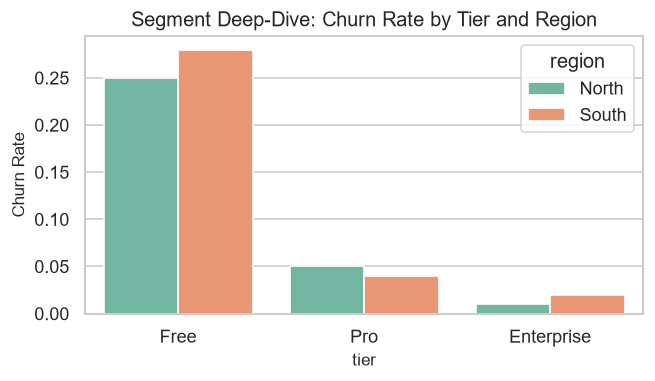

In [ ]:
df_seg = pd.DataFrame({
    'tier': ['Free', 'Free', 'Pro', 'Pro', 'Enterprise', 'Enterprise'],
    'region': ['North', 'South', 'North', 'South', 'North', 'South'],
    'churn_rate': [0.25, 0.28, 0.05, 0.04, 0.01, 0.02]
})

print( df_seg.pivot(index='tier', columns='region', values='churn_rate'),)

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='tier', y='churn_rate', hue='region', data=df_seg, palette='Set2', errorbar=None)
plt.title('Segment Deep-Dive: Churn Rate by Tier and Region')
plt.ylabel('Churn Rate')
plt.show()

#### Identifying Confounders and Simpson’s Paradox in EDA

In [ ]:
data = [
    # Batter A: Great overall, but plays mostly on brutal turning tracks (90 out of 100 innings)
    {'Batter': 'Batter A', 'Pitch': 'Flat', 'Innings': 10, 'Runs': 550},
    {'Batter': 'Batter A', 'Pitch': 'Turning', 'Innings': 90, 'Runs': 3150},
    
    # Batter B: Weaker on both pitches, but plays almost entirely on easy flat tracks (90 out of 100 innings)
    {'Batter': 'Batter B', 'Pitch': 'Flat', 'Innings': 90, 'Runs': 4500},
    {'Batter': 'Batter B', 'Pitch': 'Turning', 'Innings': 10, 'Runs': 300},
]
df = pd.DataFrame(data)
print(df)
df["Average"]= df["Runs"] / df["Innings"]
print(df)
print("_" * 60)
print(" Break down by pitch type")
print(df[['Batter', 'Pitch','Innings' ,'Average']])
print("_" * 60)
print(df.pivot(index='Batter', columns='Pitch', values='Average'))  
print("_" * 60)
overall = df.groupby('Batter').agg({'Innings': 'sum', 'Runs': 'sum'}).reset_index()
print(overall)
print("_" * 60)
overall['Overall_Average'] = overall['Runs'] / overall['Innings']
print(overall)
print("_" * 60)


     Batter    Pitch  Innings  Runs
0  Batter A     Flat       10   550
1  Batter A  Turning       90  3150
2  Batter B     Flat       90  4500
3  Batter B  Turning       10   300
     Batter    Pitch  Innings  Runs  Average
0  Batter A     Flat       10   550     55.0
1  Batter A  Turning       90  3150     35.0
2  Batter B     Flat       90  4500     50.0
3  Batter B  Turning       10   300     30.0
____________________________________________________________
 Break down by pitch type
     Batter    Pitch  Innings  Average
0  Batter A     Flat       10     55.0
1  Batter A  Turning       90     35.0
2  Batter B     Flat       90     50.0
3  Batter B  Turning       10     30.0
____________________________________________________________
Pitch     Flat  Turning
Batter                 
Batter A  55.0     35.0
Batter B  50.0     30.0
____________________________________________________________
     Batter  Innings  Runs
0  Batter A      100  3700
1  Batter B      100  4800
     Batter  I